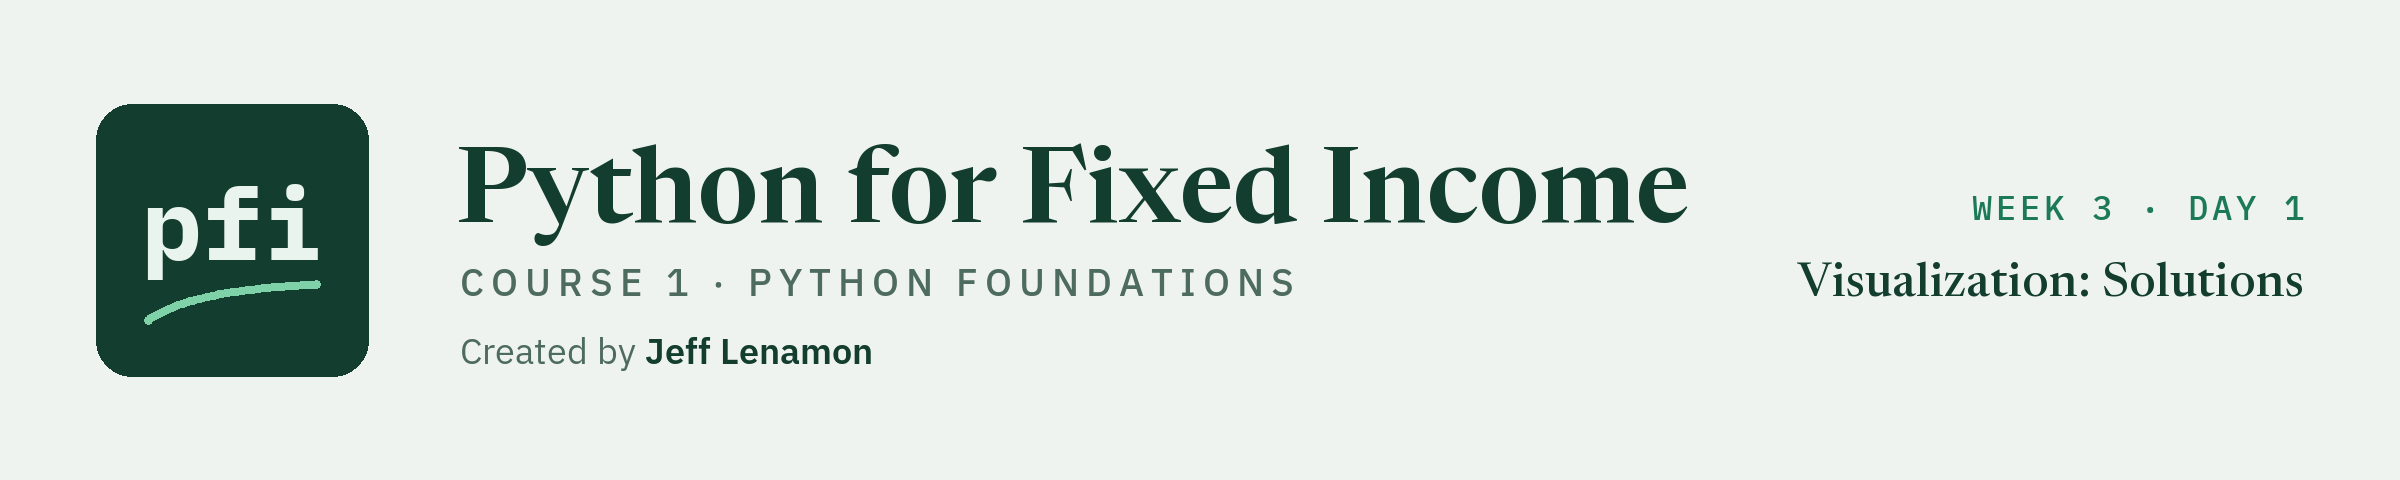

# Visualization - Solutions

Week 3, Day 1. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day1/11_visualization_solutions.ipynb)

## Exercises

These are the worked answers; the issuers are invented.
Run the next two cells first: the first defines `check`; the second reloads `book` and `bucket_order`.

In [1]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [2]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# fresh copies of the two tables, in Colab from GitHub, and today's chart theme
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
book = pd.merge(holdings, ratings, on='rating')
bucket_order = ratings.sort_values('score')['bucket'].unique().tolist()
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'],
              rc={'boxplot.medianprops.color': '#1E4D3A'})
print(book.shape)
print(bucket_order)

(200, 22)
['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC']


### Exercise 1

Q. Draw `duration` in 15 bins. Store the mean, to 2 places, in **ex1_mean** and the bonds above 10 years in **ex1_long**.

Mean duration: 6.47
Median duration: 6.31
Bonds with a duration above 10 years: 31


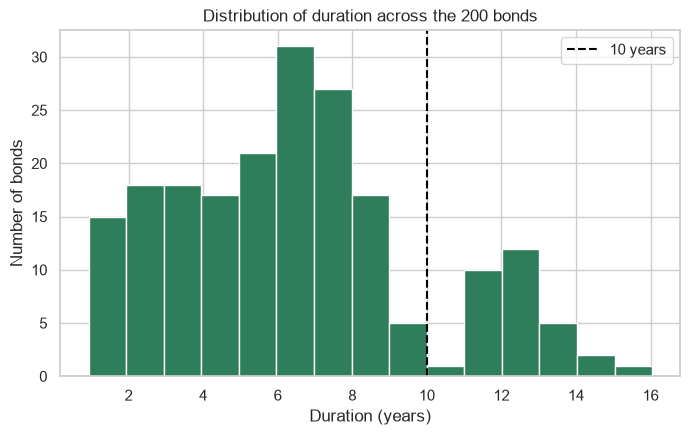

In [3]:
ex1_mean = round(book['duration'].mean(), 2)
ex1_long = (book['duration'] > 10).sum()

print('Mean duration:', ex1_mean)
print('Median duration:', round(book['duration'].median(), 2))
print('Bonds with a duration above 10 years:', ex1_long)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(book['duration'], bins=15)

# a reference line at the 10 year mark the question asks about
ax.axvline(10, color='black', linestyle='--', label='10 years')
ax.legend()

ax.set_title('Distribution of duration across the 200 bonds')
ax.set_xlabel('Duration (years)')
ax.set_ylabel('Number of bonds')

plt.show()

The mean duration is 6.47 years, and 31 bonds sit right of the dashed line at 10 years.
The mean and the median, 6.47 and 6.31, are close: duration's tail to the right, out to 16 years, is far shorter than the OAS tail, where the mean sat 50 bp above the median.

In [4]:
check('Exercise 1 mean', ex1_mean, 6.47)
check('Exercise 1 long bonds', ex1_long, 31)

Exercise 1 mean: correct
Exercise 1 long bonds: correct


### Exercise 2

Q. Draw `coupon` as a box per grade. Store the medians in **ex2_ig_median** and **ex2_hy_median**.

Median coupon, Investment Grade: 5.125
Median coupon, High Yield: 7.0
Third quartile, Investment Grade: 5.78125
First quartile, High Yield: 6.0625


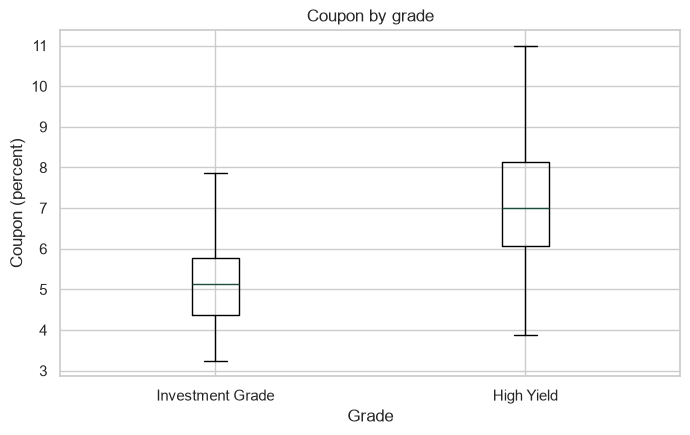

In [5]:
# the coupon column, split into the two grades
ig_coupon = book.loc[book['grade'] == 'Investment Grade', 'coupon']
hy_coupon = book.loc[book['grade'] == 'High Yield', 'coupon']

ex2_ig_median = ig_coupon.median()
ex2_hy_median = hy_coupon.median()

print('Median coupon, Investment Grade:', ex2_ig_median)
print('Median coupon, High Yield:', ex2_hy_median)

# the top of one box and the bottom of the other
print('Third quartile, Investment Grade:', ig_coupon.quantile(0.75))
print('First quartile, High Yield:', hy_coupon.quantile(0.25))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([ig_coupon, hy_coupon], tick_labels=['Investment Grade', 'High Yield'])

ax.set_title('Coupon by grade')
ax.set_xlabel('Grade')
ax.set_ylabel('Coupon (percent)')

plt.show()

The medians, the lines inside the boxes, are 5.125 percent for Investment Grade and 7.0 for High Yield.
The boxes do not overlap, 5.78125 against 6.0625, but the whiskers do: as with the OAS, the grades differ in the middle and share part of their range.

In [6]:
check('Exercise 2 Investment Grade', ex2_ig_median, 5.125)
check('Exercise 2 High Yield', ex2_hy_median, 7.0)

Exercise 2 Investment Grade: correct
Exercise 2 High Yield: correct


### Exercise 3

Q. Draw the average `duration` per bucket, in credit order. Store the tallest bar's bucket, found with 11.7's `idxmax()`, in **ex3_bucket** and its height, to 2 places, in **ex3_height**.

bucket
AAA    5.67
AA     5.70
A      6.52
BBB    7.40
BB     5.84
B      5.85
CCC    4.42
Name: duration, dtype: float64


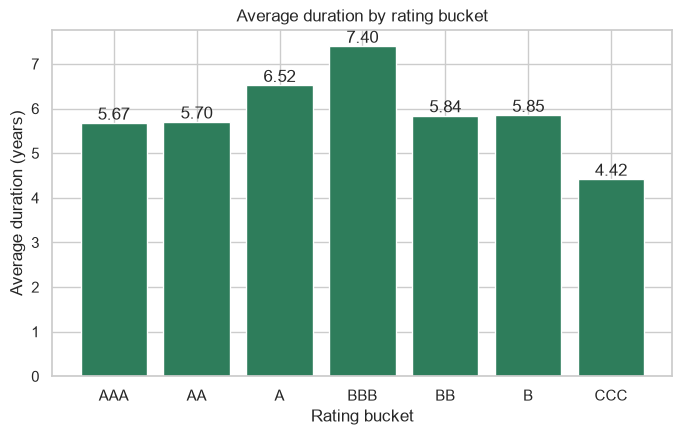

In [7]:
# the mean duration of each bucket, with the rows put in credit order
duration_by_bucket = book.groupby('bucket')['duration'].mean().loc[bucket_order]
print(duration_by_bucket.round(2))

ex3_bucket = duration_by_bucket.idxmax()
ex3_height = round(duration_by_bucket.max(), 2)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(duration_by_bucket.index, duration_by_bucket.values)
ax.bar_label(bars, fmt='%.2f')

ax.set_title('Average duration by rating bucket')
ax.set_xlabel('Rating bucket')
ax.set_ylabel('Average duration (years)')

plt.show()

BBB is the tallest bar at 7.4 years, and CCC the shortest at 4.42.
Unlike the average OAS, the average duration does not step one way along the scale: it rises from AAA to BBB and is lower in the three High Yield buckets.

In [8]:
check('Exercise 3 bucket', ex3_bucket, 'BBB')
check('Exercise 3 height', ex3_height, 7.4)

Exercise 3 bucket: correct
Exercise 3 height: correct


### Exercise 4

Q. Draw `yield_pct` against `coupon` by grade. Store their correlation, to 2 places, in **ex4_corr** and the bonds yielding above their coupon in **ex4_above**.

Correlation of coupon and yield: 0.74
Bonds with a yield above the coupon: 113
Bonds priced below 100: 113


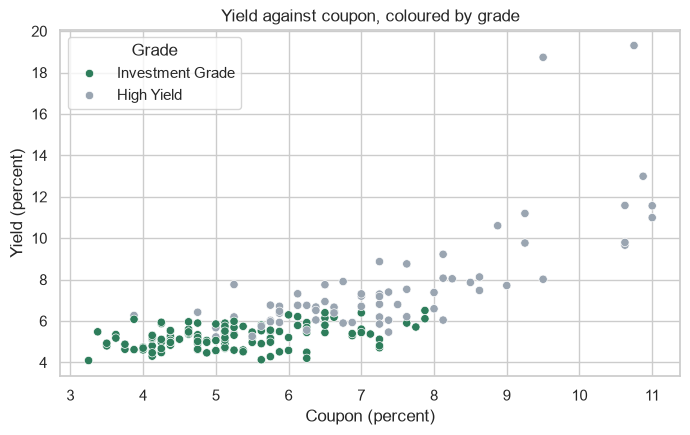

In [9]:
ex4_corr = round(book['coupon'].corr(book['yield_pct']), 2)

# a comparison of two columns gives True or False for each bond, and sum() counts the True values
ex4_above = (book['yield_pct'] > book['coupon']).sum()

print('Correlation of coupon and yield:', ex4_corr)
print('Bonds with a yield above the coupon:', ex4_above)
print('Bonds priced below 100:', (book['price'] < 100).sum())

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=book, x='coupon', y='yield_pct', hue='grade', ax=ax)
ax.legend(title='Grade')

ax.set_title('Yield against coupon, coloured by grade')
ax.set_xlabel('Coupon (percent)')
ax.set_ylabel('Yield (percent)')

plt.show()

The correlation is 0.74, the coupon row of the lesson's heatmap: a loose rising band, far looser than yield against OAS.
113 bonds yield more than their coupon, the same 113 priced below 100 that pandas Part 2 counted: a yield above the coupon means a discount price.

In [10]:
check('Exercise 4 correlation', ex4_corr, 0.74)
check('Exercise 4 above coupon', ex4_above, 113)

Exercise 4 correlation: correct
Exercise 4 above coupon: correct


### Exercise 5

Q. Write `bucket_bar_chart(column, y_label)`, which draws Exercise 3's chart for any column and returns the axes. Store `bucket_bar_chart('coupon', 'Average coupon (percent)')` in **ex5_ax**.

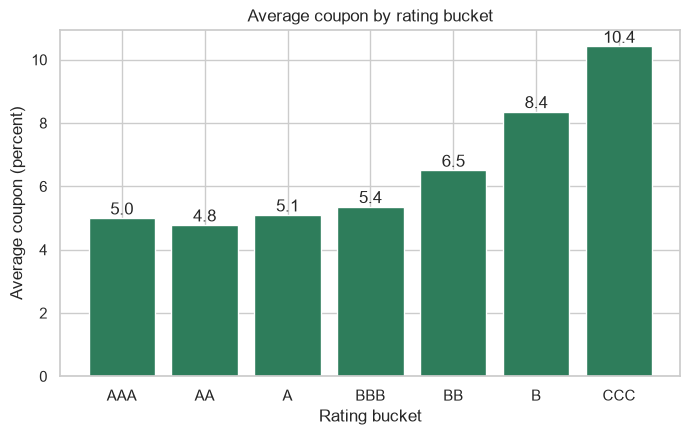

Bars drawn: 7
Average coupon, AAA to CCC: [5.0, 4.8, 5.1, 5.4, 6.5, 8.4, 10.4]
Lowest: 4.8 percent, highest: 10.4 percent


In [11]:
def bucket_bar_chart(column, y_label):
    """Draw the average of one column for each rating bucket, in credit order. Return the axes."""
    # the mean of the column in each bucket, with the rows put in credit order
    averages = book.groupby('bucket')[column].mean().loc[bucket_order]

    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(averages.index, averages.values)
    ax.bar_label(bars, fmt='%.1f')

    # the column name goes into the title with an f-string
    ax.set_title(f'Average {column} by rating bucket')
    ax.set_xlabel('Rating bucket')
    ax.set_ylabel(y_label)

    # hand the axes back to whoever called the function
    return ax


# one call draws the chart. The same call with another column draws another.
ex5_ax = bucket_bar_chart('coupon', 'Average coupon (percent)')
plt.show()

# the heights of the bars, read back from the axes the function returned, to 1 decimal place
heights = [round(float(bar.get_height()), 1) for bar in ex5_ax.patches]
print(f'Bars drawn: {len(heights)}')
print(f'Average coupon, AAA to CCC: {heights}')
print(f'Lowest: {min(heights):.1f} percent, highest: {max(heights):.1f} percent')

The average coupon runs from 5.0 percent at AAA to 10.4 at CCC, with a dip to 4.8 at AA.
`ax.patches` holds the bars drawn, and `get_height()` reads each one, which `float()` turns into a plain number: the chart is checked against numbers, not by eye.
`bucket_bar_chart('duration', 'Average duration (years)')` draws Exercise 3's chart in one line; the grouping, the order, and the labels are written once.
Returning the axes costs one line and lets the caller add a line, change the title, or check the bars.

In [12]:
# the check reads the chart back from the axes your function returned
if ex5_ax is None:
    print('Exercise 5 chart: not attempted yet')
else:
    check('Exercise 5 y label', ex5_ax.get_ylabel(), 'Average coupon (percent)')
    check('Exercise 5 bar heights', [round(float(bar.get_height()), 1) for bar in ex5_ax.patches],
          [5.0, 4.8, 5.1, 5.4, 6.5, 8.4, 10.4])
    check('Exercise 5 title', ex5_ax.get_title() != '', True)

Exercise 5 y label: correct
Exercise 5 bar heights: correct
Exercise 5 title: correct


### Exercise 6

Q. Draw `price` in bins 2 points wide, with a smooth curve. Store the bonds below 90 in **ex6_below** and the median minus the mean, to 2 places, in **ex6_gap**.

Bonds priced below 90: 21
Median minus mean: 0.59


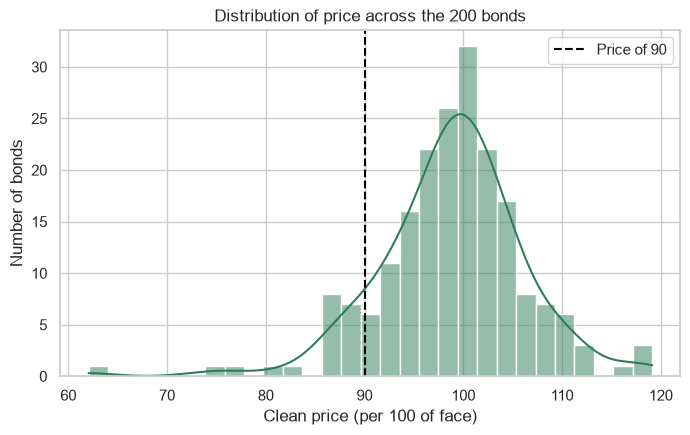

In [13]:
ex6_below = (book['price'] < 90).sum()
ex6_gap = round(book['price'].median() - book['price'].mean(), 2)

print('Bonds priced below 90:', ex6_below)
print('Median minus mean:', ex6_gap)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=book, x='price', binwidth=2, kde=True, ax=ax)

# a reference line at the price the question asks about
ax.axvline(90, color='black', linestyle='--', label='Price of 90')
ax.legend()

ax.set_title('Distribution of price across the 200 bonds')
ax.set_xlabel('Clean price (per 100 of face)')
ax.set_ylabel('Number of bonds')

plt.show()

21 bonds sit in the thin tail left of the dashed line at 90.
The median is 0.59 above the mean, pulled down by the low prices: the column is skewed left.

In [14]:
check('Exercise 6 below 90', ex6_below, 21)
check('Exercise 6 gap', ex6_gap, 0.59)

Exercise 6 below 90: correct
Exercise 6 gap: correct


### Exercise 7: AI check

You ask an AI assistant for the average OAS per bucket, in credit order.

Its code, written for this course in an AI's style, has one bug.

Q. Before you run it: how tall should the BBB bar be? Section 11.5 worked it out. Then run it.

Section 11.5's BBB average is 127.82 bp; the original code drew the BBB bar at 503.33, with no error, and the bars did not rise left to right.
The heights and the labels were in two orders: `groupby` gives A, AA, AAA, B, BB, BBB, CCC, the labels were typed in credit order, and `avg_oas.values` met them by position.
So AAA took the A average and BBB the B average: four bars, AAA, A, BBB, and B, carried the wrong name, while AA, BB, and CCC sit in the same place in both orders, which made the chart look half right.
The fix puts the values in the labels' order before drawing, `.loc[labels]`, so name and number travel together; one number worked out earlier caught it.

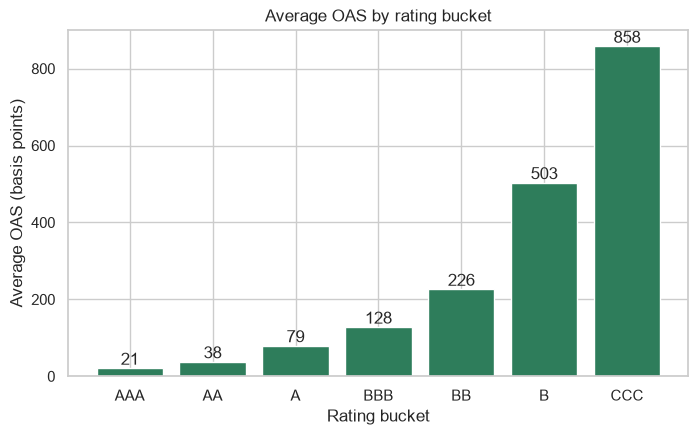

Height of the bar labelled BBB: 127.82


In [15]:
# average OAS of each rating bucket, put in credit order before it is drawn
labels = ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC']
avg_oas = book.groupby('bucket')['oas'].mean().loc[labels]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(labels, avg_oas.values)
ax.bar_label(bars, fmt='%.0f')

ax.set_title('Average OAS by rating bucket')
ax.set_xlabel('Rating bucket')
ax.set_ylabel('Average OAS (basis points)')

plt.show()

# the height of the bar that carries the label BBB
ex7_bbb = round(avg_oas.values[labels.index('BBB')], 2)
print('Height of the bar labelled BBB:', ex7_bbb)

In [16]:
check('Exercise 7 BBB bar', ex7_bbb, 127.82)
# the labels under the bars, left to right, must be the buckets in credit order
check('Exercise 7 bar order', labels, bucket_order)

Exercise 7 BBB bar: correct
Exercise 7 bar order: correct
